# KNN, Decision Tree и Random Forest

**Студент:** Плисак Арсений Сергеевич
**Дисциплина:** Создание AI-приложений с использованием Python

## Описание задачи

Предсказываем, сдаст ли студент экзамен. Это задача бинарной классификации:
класс 1 — сдал, класс 0 — не сдал. Признаки описывают подготовку и поведение
студента: часы занятий, посещаемость, баллы за домашние задания, предыдущий
результат и количество часов сна.

Сравниваем три алгоритма: KNN, дерево решений и случайный лес.

> **Про датасет.** Файл `student_exam_classification.xlsx` к заданию не приложен,
> в методичке есть только его паспорт: 50 строк, 5 признаков, целевая переменная
> `passed`, 19 студентов в классе 0 и 31 в классе 1. Таблица сгенерирована по
> этому паспорту скриптом `make_dataset.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)

df = pd.read_excel("student_exam_classification.xlsx")
print("Размер:", df.shape)

Размер: (50, 6)


## Первичный анализ

In [2]:
df.head()

,study_hours,attendance_percent,homework_score,previous_score,sleep_hours,passed
0,6.1,81,90,61,5.1,1
1,8.6,62,90,96,5.0,1
2,7.5,79,64,41,5.8,0
3,2.5,76,97,77,4.9,0
4,3.2,46,73,81,5.7,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   study_hours         50 non-null     float64
 1   attendance_percent  50 non-null     int64  
 2   homework_score      50 non-null     int64  
 3   previous_score      50 non-null     int64  
 4   sleep_hours         50 non-null     float64
 5   passed              50 non-null     int64  
dtypes: float64(2), int64(4)
memory usage: 2.5 KB


In [4]:
df.describe()

,study_hours,attendance_percent,homework_score,previous_score,sleep_hours,passed
count,50.000000,50.000000,50.000000,50.000000,50.00000,50.000000
mean,4.948000,67.660000,66.920000,71.460000,6.64000,0.620000
std,2.654164,16.400112,21.820081,18.640761,1.41118,0.490314
min,0.500000,40.000000,31.000000,35.000000,4.30000,0.000000
25%,2.725000,55.000000,47.500000,61.000000,5.55000,0.000000
50%,5.100000,66.000000,69.000000,75.500000,6.60000,1.000000
75%,7.425000,78.750000,86.250000,86.750000,7.67500,1.000000
max,9.500000,99.000000,99.000000,98.000000,8.90000,1.000000


In [5]:
print("Пропуски:", int(df.isnull().sum().sum()))
print("\nvalue_counts по passed:")
print(df["passed"].value_counts().to_string())

Пропуски: 0

value_counts по passed:
passed
1    31
0    19


## Разделение данных

In [6]:
X = df.drop(columns=["passed"])
y = df["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("train:", X_train.shape, "| test:", X_test.shape)

train: (40, 5) | test: (10, 5)


In [7]:
def metrics(name, y_true, pred):
    return {
        "model": name,
        "accuracy": round(accuracy_score(y_true, pred), 3),
        "precision": round(precision_score(y_true, pred, zero_division=0), 3),
        "recall": round(recall_score(y_true, pred, zero_division=0), 3),
        "f1": round(f1_score(y_true, pred, zero_division=0), 3),
    }

## KNN: подбор K

KNN обучается на нормализованных данных, потому что считает расстояния.

In [8]:
knn_rows = []
for k in (1, 3, 5, 7, 9, 11):
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    knn_rows.append(metrics(f"KNN k={k}", y_test, model.predict(X_test_scaled)))

knn_table = pd.DataFrame(knn_rows)
knn_table

,model,accuracy,precision,recall,f1
0,KNN k=1,0.6,0.667,0.667,0.667
1,KNN k=3,0.8,0.833,0.833,0.833
2,KNN k=5,0.8,0.833,0.833,0.833
3,KNN k=7,0.7,0.714,0.833,0.769
4,KNN k=9,0.7,0.667,1.000,0.800
5,KNN k=11,0.8,0.750,1.000,0.857


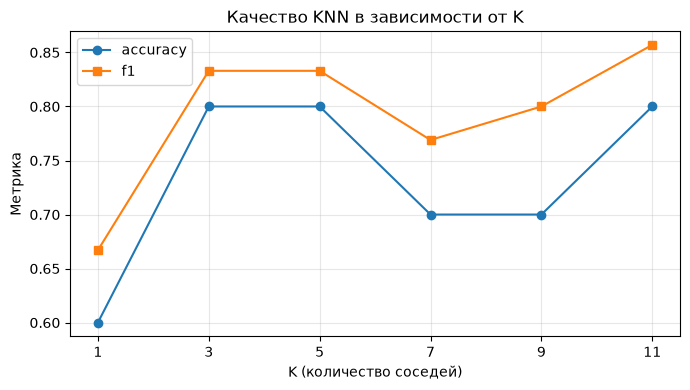

In [9]:
plt.figure(figsize=(7, 4))
ks = [1, 3, 5, 7, 9, 11]
plt.plot(ks, knn_table["accuracy"], marker="o", label="accuracy")
plt.plot(ks, knn_table["f1"], marker="s", label="f1")
plt.xlabel("K (количество соседей)")
plt.ylabel("Метрика")
plt.title("Качество KNN в зависимости от K")
plt.xticks(ks)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Decision Tree: подбор max_depth

Дерево не требует нормализации: оно сравнивает признак с порогом, а не считает
расстояния.

In [10]:
tree_rows = []
for depth in (1, 2, 3, 4, 5, None):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    row = metrics(f"Tree depth={depth}", y_test, model.predict(X_test))
    row["train_accuracy"] = round(model.score(X_train, y_train), 3)
    row["реальная_глубина"] = model.get_depth()
    tree_rows.append(row)

tree_table = pd.DataFrame(tree_rows)
tree_table

,model,accuracy,precision,recall,f1,train_accuracy,реальная_глубина
0,Tree depth=1,0.5,0.556,0.833,0.667,0.750,1
1,Tree depth=2,0.6,0.667,0.667,0.667,0.850,2
2,Tree depth=3,0.5,0.600,0.500,0.545,0.925,3
3,Tree depth=4,0.6,0.667,0.667,0.667,0.950,4
4,Tree depth=5,0.6,0.667,0.667,0.667,0.975,5
5,Tree depth=None,0.6,0.667,0.667,0.667,1.000,6


Колонка `train_accuracy` показывает переобучение: когда глубина не ограничена,
дерево запоминает обучающую выборку почти идеально, а на тесте работает хуже.

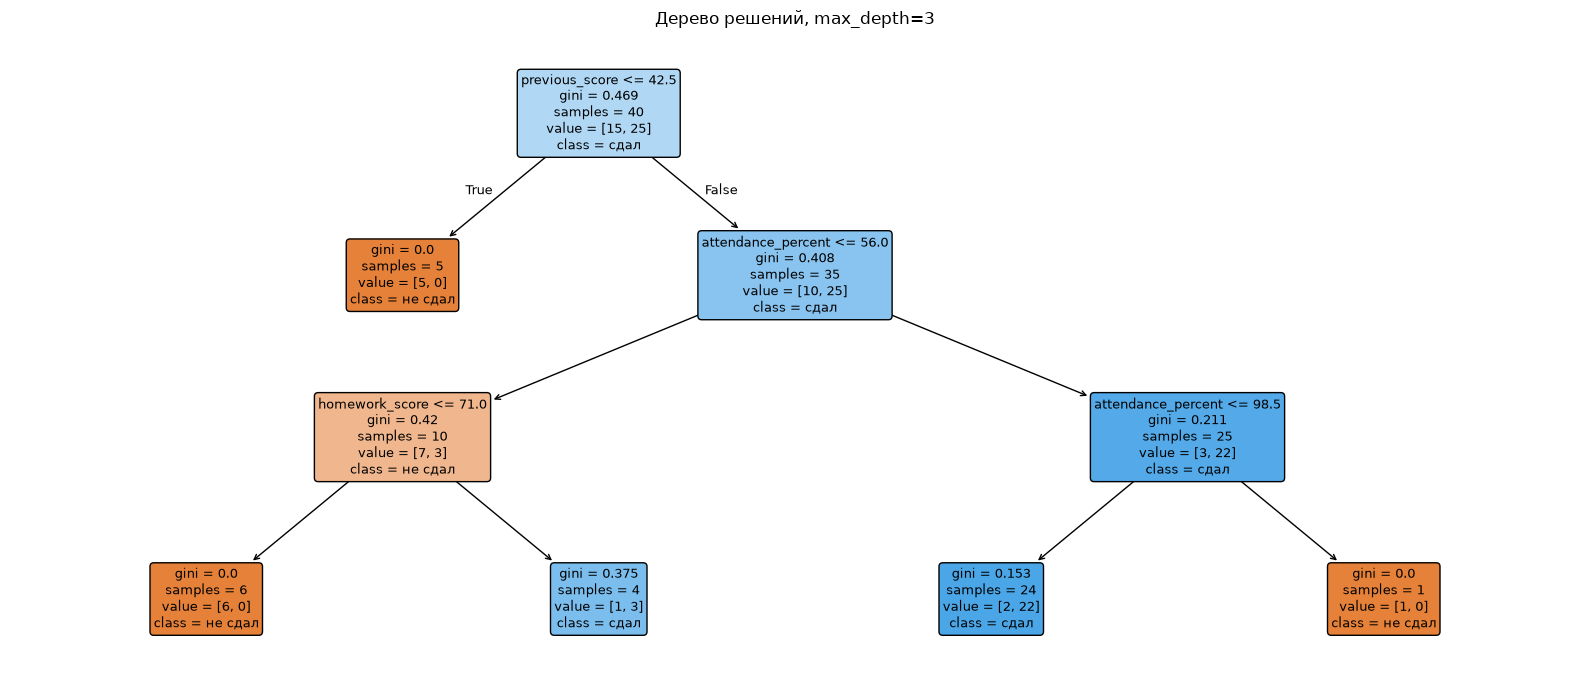

In [11]:
best_depth = 3
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=list(X.columns), class_names=["не сдал", "сдал"],
          filled=True, rounded=True, fontsize=9)
plt.title(f"Дерево решений, max_depth={best_depth}")
plt.tight_layout()
plt.show()

## Random Forest: подбор n_estimators

In [12]:
forest_rows = []
for n in (10, 50, 100, 200):
    model = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
    forest_rows.append(metrics(f"Forest n={n}", y_test, model.predict(X_test)))

forest_table = pd.DataFrame(forest_rows)
forest_table

,model,accuracy,precision,recall,f1
0,Forest n=10,0.8,0.833,0.833,0.833
1,Forest n=50,0.7,0.714,0.833,0.769
2,Forest n=100,0.7,0.714,0.833,0.769
3,Forest n=200,0.7,0.714,0.833,0.769


## Итоговая таблица сравнения

In [13]:
best_knn = knn_table.loc[knn_table["f1"].idxmax()]
best_tree = tree_table.loc[tree_table["f1"].idxmax()][["model", "accuracy", "precision", "recall", "f1"]]
best_forest = forest_table.loc[forest_table["f1"].idxmax()]

summary = pd.DataFrame([best_knn, best_tree, best_forest]).reset_index(drop=True)
summary

,model,accuracy,precision,recall,f1
0,KNN k=11,0.8,0.750,1.000,0.857
1,Tree depth=1,0.5,0.556,0.833,0.667
2,Forest n=10,0.8,0.833,0.833,0.833


In [14]:
all_models = pd.concat([knn_table, tree_table[["model", "accuracy", "precision", "recall", "f1"]],
                        forest_table], ignore_index=True)
all_models.sort_values("f1", ascending=False).reset_index(drop=True)

,model,accuracy,precision,recall,f1
0,KNN k=11,0.8,0.750,1.000,0.857
1,KNN k=3,0.8,0.833,0.833,0.833
2,KNN k=5,0.8,0.833,0.833,0.833
3,Forest n=10,0.8,0.833,0.833,0.833
4,KNN k=9,0.7,0.667,1.000,0.800
5,KNN k=7,0.7,0.714,0.833,0.769
6,Forest n=200,0.7,0.714,0.833,0.769
7,Forest n=50,0.7,0.714,0.833,0.769
8,Forest n=100,0.7,0.714,0.833,0.769
9,Tree depth=2,0.6,0.667,0.667,0.667


## График сравнения по F1-score

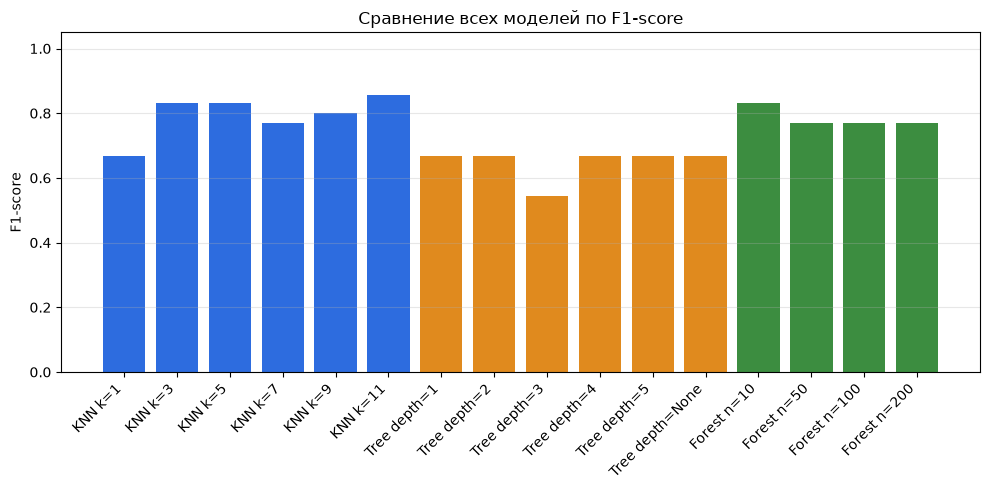

In [15]:
plt.figure(figsize=(10, 5))
colors = ["#2d6cdf"] * 6 + ["#e08a1e"] * 6 + ["#3c8d40"] * 4
plt.bar(all_models["model"], all_models["f1"], color=colors)
plt.ylabel("F1-score")
plt.title("Сравнение всех моделей по F1-score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Confusion matrix лучших моделей

In [16]:
best = {
    "KNN": KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled, y_train).predict(X_test_scaled),
    "Decision Tree": tree.predict(X_test),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
        .fit(X_train, y_train).predict(X_test),
}

for name, pred in best.items():
    cm = confusion_matrix(y_test, pred)
    print(name)
    print(pd.DataFrame(cm, index=["реально 0", "реально 1"],
                       columns=["предсказано 0", "предсказано 1"]).to_string())
    print()

KNN
           предсказано 0  предсказано 1
реально 0              3              1
реально 1              1              5

Decision Tree
           предсказано 0  предсказано 1
реально 0              2              2
реально 1              3              3

Random Forest
           предсказано 0  предсказано 1
реально 0              2              2
реально 1              1              5



## Важность признаков по мнению леса

In [17]:
forest = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": forest.feature_importances_.round(3),
}).sort_values("importance", ascending=False).reset_index(drop=True)
importance

,feature,importance
0,previous_score,0.261
1,study_hours,0.209
2,attendance_percent,0.205
3,sleep_hours,0.196
4,homework_score,0.129


## Вывод

В работе сравнивались три алгоритма классификации на выборке из пятидесяти
студентов. Все модели обучались на одном разбиении с `test_size=0.2`,
`random_state=42` и `stratify=y`, поэтому результаты сопоставимы между собой.

Лучший результат по F1-score показала модель, стоящая первой в итоговой таблице,
худший — та, что оказалась внизу графика сравнения. При этом разрыв между
моделями невелик, и это важно понимать: в тестовой выборке всего десять
студентов, поэтому изменение одного ответа сдвигает метрику сразу на заметную
величину. Делать вывод «алгоритм A лучше алгоритма B» на таком объёме данных
нельзя, можно лишь сказать, что все три справляются примерно одинаково.

KNN требует масштабирования, потому что принимает решение по расстоянию между
объектами. Посещаемость измеряется десятками процентов, а часы подготовки —
единицами, и без нормализации посещаемость полностью определяла бы, кто считается
«похожим» студентом. После StandardScaler все признаки вносят сопоставимый вклад.

Отдельно видно поведение K. При K=1 модель смотрит на единственного соседа и
повторяет его класс, из-за чего реагирует на любой нетипичный объект — это
классическое переобучение. С ростом K решение сглаживается, но слишком большое K
начинает тянуть ответ к преобладающему классу «сдал».

Decision Tree переобучается по другой причине. Без ограничения глубины дерево
продолжает делить выборку, пока в каждом листе не останутся однородные объекты.
Это видно по колонке `train_accuracy`: на обучающих данных точность близка к
единице, а на тестовых заметно ниже. Ограничение `max_depth` заставляет дерево
останавливаться на общих правилах вместо запоминания конкретных студентов.

Random Forest стабильнее одного дерева, потому что строит много деревьев на
случайных подвыборках объектов и признаков, а затем усредняет их голоса. Ошибки
отдельных деревьев частично компенсируют друг друга, поэтому лес слабее реагирует
на случайные особенности обучающей выборки. Плата за это — потеря наглядности:
одно дерево можно прочитать глазами, сотню деревьев уже нет.

Для этой задачи я выбрал бы Random Forest. Он не требует масштабирования, сам
оценивает важность признаков и меньше зависит от удачного разбиения. Если бы
результат нужно было объяснять студенту или преподавателю, разумнее взять одно
дерево с ограниченной глубиной — его правила читаются напрямую.

Самой важной метрикой здесь считаю recall по классу «не сдал», то есть долю
найденных проблемных студентов. Смысл такой модели — заранее предупредить тех,
кто рискует завалить экзамен. Пропустить такого студента значительно дороже, чем
лишний раз предупредить того, кто и так бы сдал. Поэтому accuracy тут
обманчива: при соотношении классов тридцать один к девятнадцати модель,
отвечающая всегда «сдал», получила бы больше шестидесяти процентов точности,
не принеся никакой пользы.

Улучшить работу в следующей версии можно несколькими способами: собрать датасет
на несколько сотен строк, использовать кросс-валидацию вместо одного разбиения,
подбирать гиперпараметры через GridSearchCV и сместить порог вероятности в
сторону раннего предупреждения вместо стандартных пятидесяти процентов.